# Head Pose Estimation (HPE) with MobileNetV3: final design (COS30082 individual innovation feature)

**Design**, adopted from the community project [yakhyo/head-pose-estimation](https://github.com/yakhyo/head-pose-estimation) (MIT licence), which builds on 6DRepNet's 6D rotation representation and geodesic loss:

* **Backbone:** torchvision MobileNetV3 (`mobilenetv3_large` by default, `mobilenetv3_small` optional), initialised from generic ImageNet weights.
* **Head:** global average pool -> `Linear(960, 1280)` -> Hardswish -> `Linear(1280, 6)` (their `linear_reg`; 576/1024 for Small).
* **6D -> rotation matrix** by Gram-Schmidt, then **geodesic loss** against the ground-truth rotation matrix. Angles (pitch, yaw, roll) are read back from the matrix.

**Adopted vs not adopted**

* Adopted: the architecture above, the loss, the conventions, and the 300W-LP -> AFLW2000 protocol (|angle| <= 99 deg). I read their code to confirm these (`models/mobilenetv3.py`, `utils/loss.py`, `utils/general.py`, `utils/datasets.py`).
* **Not adopted: their trained weights.** The repo ships head-pose weights; none are loaded here. The only pretrained weights are the backbone's generic ImageNet ones, and the head is trained from scratch by me.
* Not adopted: their face detector and their 80-epoch full fine-tuning recipe. Ours is a 20-epoch staged schedule with partial fine-tuning (below).
* Ours: identity-initialised output bias (training starts at "facing the camera"), staged partial fine-tuning, validation split by source photo, input validation, resumable training, tests, inference class and pose gate.

**Reference numbers (the repo's README, not reproduced by me):** AFLW2000 MAE 5.74 deg for MobileNetV3-Large and 7.47 deg for Small, from the author's own 80-epoch, full fine-tuning runs. Do not expect to match them with 20 epochs and partial fine-tuning; compare your own runs against each other.

**What is trained, exactly (state this precisely in the report)**

* `partial` schedule (**default**): head only -> then the deepest 3 of 17 feature blocks (`features.14-16`) plus the head -> same blocks at a lower LR. The stem and `features.1-13` (`features.0-13` in all) are **never trained**. MobileNetV3's weights sit in the last blocks, so those 3 blocks still hold about 59% of the backbone's weights, and the head MLP adds 1.24 M: about **71% of all parameters train** (29% frozen), and the head-only phase alone trains 29%. Each phase prints the exact share, so quote that line.
* `full` schedule (ablation, closest to the community recipe): identical until the last phase, which unfreezes everything.

**Protocol:** train on 300W-LP (validation split by source photo), test **once** on the full AFLW2000 (|angle| <= 99 deg, never trained on), report MAE for yaw / pitch / roll plus parameters and inference speed.

**Run order:** GPU runtime -> run all cells top to bottom. Section 8 has `QUICK_RUN` (smoke test) and `PRESET` (`partial` / `full`). Training state is saved after every epoch, so a Colab disconnect costs at most one epoch.


## 1. Imports


In [ ]:
import copy
import dataclasses
import json
import math
import os
import random
import tempfile
import time
import zipfile
from collections import OrderedDict
from collections.abc import Iterable, Iterator, Sequence
from concurrent.futures import ThreadPoolExecutor
from dataclasses import dataclass
from pathlib import Path
from typing import NamedTuple, Optional

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torchvision
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import display
from PIL import Image, ImageOps
from scipy.io import loadmat
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms as T
from tqdm.auto import tqdm

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", DEVICE, "| torch", torch.__version__, "| torchvision", torchvision.__version__)

device: cuda | torch 2.14.1+cu130 | torchvision 0.29.1+cu130


## 2. Configuration

In [ ]:
HEADS = ("6d", "euler")
VARIANT_NAMES = ("mobilenetv3_large", "mobilenetv3_small")
ANGLE_NAMES = ("pitch", "yaw", "roll")  # order stored in the 300W-LP / AFLW2000 Pose_Para

# Tunables, named so they are visible and reportable
MAX_ABS_DEG = 99.0                # AFLW2000 protocol: drop samples with any |angle| above this
TEST_MARGIN = 0.25                # crop margin (fraction of face size) at test / inference time
TRAIN_MARGIN_RANGE = (0.1, 0.4)   # random crop margin in training
TRAIN_CENTER_JITTER = 0.05        # random crop-centre shift (fraction of crop side), mimics detector noise
MIN_FACE_PX = 16.0                # smaller landmark boxes are treated as bad annotations
MAX_BAD_FRACTION = 0.005          # abort if more than 0.5% of annotations are unusable
INDEX_THREADS = 16


@dataclass(frozen=True)
class Phase:
    """One stage of partial fine-tuning.

    block_frac: fraction of the backbone's feature blocks (deepest first) that are trainable.
    0.0 = head only, 0.12 = deepest 3 of 17 blocks (Large), 1.0 = whole network.
    """
    epochs: int
    block_frac: float
    lr_head: float
    lr_backbone: float

    def __post_init__(self):
        if self.epochs < 1 or not 0.0 <= self.block_frac <= 1.0:
            raise ValueError(f"invalid phase: {self}")
        if self.block_frac > 0 and self.lr_backbone <= 0:
            raise ValueError("lr_backbone must be > 0 when the backbone is unfrozen")


FULL_PHASES = (Phase(3, 0.0, 1e-3, 0.0), Phase(8, 0.12, 3e-4, 1e-4), Phase(9, 1.0, 1e-4, 2e-5))
QUICK_PHASES = (Phase(1, 0.0, 1e-3, 0.0), Phase(2, 0.12, 3e-4, 1e-4), Phase(2, 1.0, 1e-4, 2e-5))

# Partial presets (default): the early feature blocks (features.0-13 for Large) are never trained.
PARTIAL_PHASES = (Phase(3, 0.0, 1e-3, 0.0), Phase(8, 0.12, 3e-4, 1e-4), Phase(9, 0.12, 1e-4, 2e-5))
QUICK_PARTIAL_PHASES = (Phase(1, 0.0, 1e-3, 0.0), Phase(2, 0.12, 3e-4, 1e-4), Phase(2, 0.12, 1e-4, 2e-5))


PHASE_PRESETS = {
    ("partial", False): PARTIAL_PHASES, ("partial", True): QUICK_PARTIAL_PHASES,
    ("full", False): FULL_PHASES, ("full", True): QUICK_PHASES,
}


@dataclass(frozen=True)
class Config:
    data_300wlp: str
    data_aflw2000: str
    work_dir: str
    variant: str = "mobilenetv3_large"
    head: str = "6d"
    run_name: str = ""
    img_size: int = 224
    batch_size: int = 64
    num_workers: int = min(8, os.cpu_count() or 2)
    seed: int = 42
    resume: bool = True  # continue from <tag>_last.pt if it exists (same config required)
    deterministic: bool = True  # cudnn.deterministic; False = cudnn.benchmark (faster, not bit-reproducible)
    val_fraction: float = 0.05
    max_train_samples: Optional[int] = None
    include_flip_folders: bool = False  # 300W-LP *_Flip folders; we flip randomly instead
    max_abs_deg: float = MAX_ABS_DEG
    weight_decay: float = 1e-4
    grad_clip: float = 5.0
    phases: tuple = FULL_PHASES

    def __post_init__(self):
        if self.variant not in VARIANT_NAMES:
            raise ValueError(f"variant must be one of {VARIANT_NAMES}")
        if self.head not in HEADS:
            raise ValueError(f"head must be one of {HEADS}")

    @property
    def tag(self) -> str:
        return f"{self.variant}_{self.head}" + (f"_{self.run_name}" if self.run_name else "")

## 3. Data


In [ ]:
from google.colab import drive

drive.mount("/content/drive")

DATA_ROOT = Path("/content/data")
WORK_DIR = Path("/content/drive/MyDrive/cos30082_hpe")
ZIP_300W_LP = Path("/content/drive/MyDrive/datasets/300W_LP.zip")
ZIP_AFLW2000 = Path("/content/drive/MyDrive/datasets/AFLW2000-3D.zip")

WORK_DIR.mkdir(parents=True, exist_ok=True)


def extract_once(zip_path: Path, dest: Path) -> None:
    if not zip_path.exists():
        raise FileNotFoundError(f"zip not found: {zip_path}")
    marker = dest / f".extracted_{zip_path.stem}"
    if marker.exists():
        return
    dest.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(zip_path) as zf:
        zf.extractall(dest)
    marker.touch()


def find_dir_containing(root: Path, name: str) -> Path:
    for dirpath, dirnames, filenames in os.walk(root):
        if name in dirnames or name in filenames:
            return Path(dirpath)
    raise FileNotFoundError(f"'{name}' not found under {root}")


extract_once(ZIP_300W_LP, DATA_ROOT)
extract_once(ZIP_AFLW2000, DATA_ROOT)
ROOT_300W_LP = find_dir_containing(DATA_ROOT, "AFW")
ROOT_AFLW2000 = find_dir_containing(DATA_ROOT, "image00002.jpg")
print("300W-LP:", ROOT_300W_LP, "| subfolders:", sorted(p.name for p in ROOT_300W_LP.iterdir() if p.is_dir()))
print("AFLW2000:", ROOT_AFLW2000, "| jpgs:", len(list(ROOT_AFLW2000.glob("*.jpg"))))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
300W-LP: /content/data/300W_LP | subfolders: ['AFW', 'AFW_Flip', 'Code', 'HELEN', 'HELEN_Flip', 'IBUG', 'IBUG_Flip', 'LFPW', 'LFPW_Flip', 'landmarks']
AFLW2000: /content/data/AFLW2000 | jpgs: 2000


## 4. Rotation maths

Convention (used consistently for labels, loss and evaluation): `R = Rz(roll) @ Ry(yaw) @ Rx(pitch)`, angles in radians, stored as `(pitch, yaw, roll)`.

* **6D head:** network outputs 6 numbers -> Gram-Schmidt -> rotation matrix -> geodesic loss against the ground-truth matrix.
* **Euler head (baseline):** network outputs 3 angles -> MSE.
* Horizontal flip augmentation == `yaw -> -yaw`, `roll -> -roll` (checked in the sanity tests).

In [ ]:
def euler_to_matrix_np(pitch: float, yaw: float, roll: float) -> np.ndarray:
    """R = Rz(roll) @ Ry(yaw) @ Rx(pitch); radians; returns float32 (3, 3)."""
    cx, sx = np.cos(pitch), np.sin(pitch)
    cy, sy = np.cos(yaw), np.sin(yaw)
    cz, sz = np.cos(roll), np.sin(roll)
    rx = np.array([[1, 0, 0], [0, cx, -sx], [0, sx, cx]])
    ry = np.array([[cy, 0, sy], [0, 1, 0], [-sy, 0, cy]])
    rz = np.array([[cz, -sz, 0], [sz, cz, 0], [0, 0, 1]])
    return (rz @ ry @ rx).astype(np.float32)


def rot6d_to_matrix(raw: torch.Tensor) -> torch.Tensor:
    """(B, 6) -> (B, 3, 3) rotation matrices (columns x, y, z) via Gram-Schmidt."""
    raw = raw.float()
    x = F.normalize(raw[:, 0:3], dim=1)
    z = F.normalize(torch.cross(x, raw[:, 3:6], dim=1), dim=1)
    y = torch.cross(z, x, dim=1)
    return torch.stack((x, y, z), dim=2)


def matrix_to_euler(rot: torch.Tensor) -> torch.Tensor:
    """(B, 3, 3) -> (B, 3) radians in (pitch, yaw, roll); inverse of euler_to_matrix_np."""
    pitch = torch.atan2(rot[:, 2, 1], rot[:, 2, 2])
    yaw = torch.asin((-rot[:, 2, 0]).clamp(-1.0, 1.0))
    roll = torch.atan2(rot[:, 1, 0], rot[:, 0, 0])
    return torch.stack((pitch, yaw, roll), dim=1)


def geodesic_loss(pred: torch.Tensor, target: torch.Tensor, eps: float = 1e-7) -> torch.Tensor:
    """Mean geodesic distance (radians) between batches of rotation matrices."""
    rel = pred @ target.transpose(1, 2)
    cos = (rel.diagonal(dim1=1, dim2=2).sum(-1) - 1.0) / 2.0
    return torch.acos(cos.clamp(-1.0 + eps, 1.0 - eps)).mean()


def draw_axis(
    img: np.ndarray, yaw: float, pitch: float, roll: float,
    cx: Optional[float] = None, cy: Optional[float] = None, size: int = 80,
) -> np.ndarray:
    """Draw the head's X (red), Y (green), Z (blue) axes. Angles in degrees.

    If the arrows look mirrored for your data, flip the sign of `yaw` below once.
    """
    pitch, yaw, roll = (math.radians(pitch), -math.radians(yaw), math.radians(roll))
    h, w = img.shape[:2]
    cx = w / 2 if cx is None else cx
    cy = h / 2 if cy is None else cy
    x1 = size * (math.cos(yaw) * math.cos(roll)) + cx
    y1 = size * (math.cos(pitch) * math.sin(roll) + math.cos(roll) * math.sin(pitch) * math.sin(yaw)) + cy
    x2 = size * (-math.cos(yaw) * math.sin(roll)) + cx
    y2 = size * (math.cos(pitch) * math.cos(roll) - math.sin(pitch) * math.sin(yaw) * math.sin(roll)) + cy
    x3 = size * math.sin(yaw) + cx
    y3 = size * (-math.cos(yaw) * math.sin(pitch)) + cy
    out = img.copy()
    for (x, y), color in (((x1, y1), (255, 0, 0)), ((x2, y2), (0, 255, 0)), ((x3, y3), (0, 0, 255))):
        cv2.line(out, (int(cx), int(cy)), (int(x), int(y)), color, 3)
    return out

## 5. Dataset

* `build_index` reads each `.mat` once (pose + landmark bounding box) and caches it to `work_dir`.
* Validation is split **by source image** (300W-LP makes several synthetic variants per photo; a random split would leak).
* The face crop comes from the landmark box + a random margin and centre jitter in training. That jitter is deliberate: the group's real face detector will not crop exactly like the landmark box.

In [ ]:
def _read_annotation(mat_path: Path) -> tuple[np.ndarray, np.ndarray]:
    """Return (pitch/yaw/roll in radians, landmark box x0,y0,x1,y1); raises ValueError on bad data."""
    mat = loadmat(str(mat_path), variable_names=["Pose_Para", "pt2d"])
    pose = np.asarray(mat["Pose_Para"]).reshape(-1)[:3].astype(np.float32)  # pitch, yaw, roll (rad)
    pts = np.asarray(mat["pt2d"], dtype=np.float32)
    bbox = np.array([pts[0].min(), pts[1].min(), pts[0].max(), pts[1].max()], dtype=np.float32)
    if pose.shape != (3,) or not (np.isfinite(pose).all() and np.isfinite(bbox).all()):
        raise ValueError("non-finite or malformed pose / landmarks")
    if max(bbox[2] - bbox[0], bbox[3] - bbox[1]) < MIN_FACE_PX:
        raise ValueError("degenerate landmark box")
    return pose, bbox


def _safe_read(jpg: Path) -> tuple[Optional[tuple[np.ndarray, np.ndarray]], Optional[str]]:
    """Return (annotation, None) or (None, reason). Only expected data errors are caught."""
    try:
        return _read_annotation(jpg.with_suffix(".mat")), None
    except (OSError, KeyError, ValueError, NotImplementedError) as exc:
        return None, f"{jpg.name}: {type(exc).__name__}: {exc}"


def build_index(root: Path, subfolders: Sequence[str], cache_path: Path) -> dict:
    """Return {"paths": (N,), "poses": (N, 3), "bboxes": (N, 4)}; cached on disk."""
    if cache_path.exists():
        data = np.load(cache_path, allow_pickle=False)
        return {k: data[k] for k in data.files}
    jpgs = sorted(p for sub in subfolders for p in (root / sub).glob("*.jpg"))
    if not jpgs:
        raise FileNotFoundError(f"no jpg files under {root} / {list(subfolders)}")
    with ThreadPoolExecutor(max_workers=INDEX_THREADS) as pool:
        results = list(tqdm(pool.map(_safe_read, jpgs), total=len(jpgs), desc=f"index {root.name}"))
    errors = [err for _, err in results if err is not None]
    if len(errors) > MAX_BAD_FRACTION * len(jpgs):
        raise RuntimeError(f"{len(errors)}/{len(jpgs)} annotations unusable under {root}, e.g. {errors[:3]}")
    if errors:
        print(f"skipped {len(errors)} bad annotations, e.g. {errors[:2]}")
    keep = [(p, ann) for p, (ann, err) in zip(jpgs, results, strict=True) if err is None]
    print(f"{len(keep)}/{len(jpgs)} usable samples")
    index = {
        "paths": np.array([str(p) for p, _ in keep]),
        "poses": np.stack([r[0] for _, r in keep]),
        "bboxes": np.stack([r[1] for _, r in keep]),
    }
    np.savez(cache_path, **index)
    return index


def select(index: dict, selector: np.ndarray) -> dict:
    return {k: v[selector] for k, v in index.items()}


def filter_by_angle(index: dict, max_abs_deg: float) -> dict:
    ok = (np.abs(np.degrees(index["poses"])) <= max_abs_deg).all(axis=1)
    return select(index, ok)


def split_by_source(index: dict, val_fraction: float, seed: int) -> tuple[dict, dict]:
    groups = np.array([Path(p).stem.rsplit("_", 1)[0] for p in index["paths"]])
    unique = np.unique(groups)
    np.random.default_rng(seed).shuffle(unique)
    val_groups = set(unique[: max(1, int(len(unique) * val_fraction))])
    is_val = np.array([g in val_groups for g in groups])
    return select(index, ~is_val), select(index, is_val)


def crop_face(img: Image.Image, bbox: Sequence[float], margin: float, jitter: float = 0.0) -> Image.Image:
    """Square crop around bbox, side = max(w, h) * (1 + 2 * margin); out-of-image area is black."""
    x0, y0, x1, y1 = [float(v) for v in bbox]
    cx, cy = (x0 + x1) / 2, (y0 + y1) / 2
    side = max(x1 - x0, y1 - y0) * (1 + 2 * margin)
    cx += random.uniform(-jitter, jitter) * side
    cy += random.uniform(-jitter, jitter) * side
    half = side / 2
    return img.crop((int(cx - half), int(cy - half), int(cx + half), int(cy + half)))


class PoseDataset(Dataset):
    """Returns (image in [0, 1], rotation matrix, euler (pitch, yaw, roll) in radians)."""

    def __init__(self, index: dict, train: bool, img_size: int = 224):
        self.paths, self.poses, self.bboxes = index["paths"], index["poses"], index["bboxes"]
        self.train, self.img_size = train, img_size
        self.color = T.Compose([
            T.ColorJitter(0.3, 0.3, 0.3, 0.03),
            T.RandomApply([T.GaussianBlur(5, (0.1, 1.5))], p=0.2),
        ])

    def __len__(self) -> int:
        return len(self.paths)

    def __getitem__(self, i: int) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
        img = Image.open(self.paths[i]).convert("RGB")
        pitch, yaw, roll = (float(v) for v in self.poses[i])
        x0, y0, x1, y1 = (float(v) for v in self.bboxes[i])
        if self.train:
            if random.random() < 0.5:  # mirror: yaw and roll change sign, pitch is unchanged
                img = ImageOps.mirror(img)
                x0, x1 = img.width - x1, img.width - x0
                yaw, roll = -yaw, -roll
            face = crop_face(img, (x0, y0, x1, y1), margin=random.uniform(*TRAIN_MARGIN_RANGE), jitter=TRAIN_CENTER_JITTER)
        else:
            face = crop_face(img, (x0, y0, x1, y1), margin=TEST_MARGIN)
        face = face.resize((self.img_size, self.img_size), Image.BILINEAR)
        if self.train:
            face = self.color(face)
        tensor = torch.from_numpy(np.asarray(face, dtype=np.uint8).copy()).permute(2, 0, 1).float().div_(255.0)
        euler = np.array([pitch, yaw, roll], dtype=np.float32)
        rot = euler_to_matrix_np(pitch, yaw, roll)
        return tensor, torch.from_numpy(rot), torch.from_numpy(euler)

## 6. Visual label check
Ground-truth axes drawn on test crops. If the arrows clearly disagree with the head direction, flip the sign convention in `draw_axis` before trusting any demo.

AFLW2000 test samples: 1969


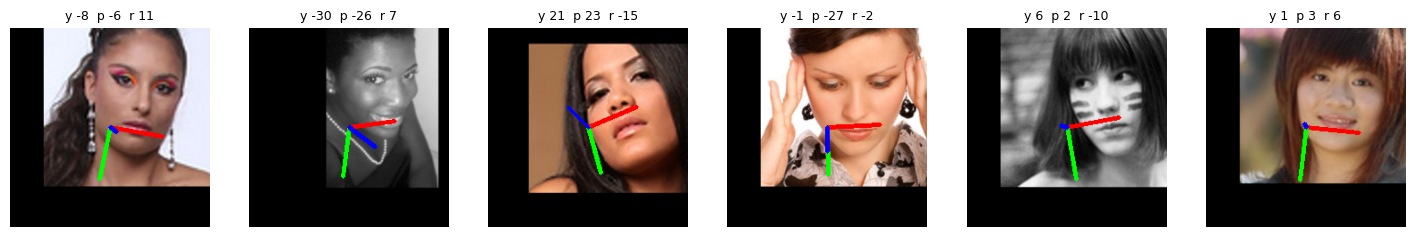

In [ ]:
aflw_index = filter_by_angle(
    build_index(ROOT_AFLW2000, [""], WORK_DIR / "index_aflw2000.npz"), MAX_ABS_DEG
)
print("AFLW2000 test samples:", len(aflw_index["paths"]))

check_ds = PoseDataset(aflw_index, train=False)
picks = np.random.default_rng(0).choice(len(check_ds), 6, replace=False)
fig, axes = plt.subplots(1, 6, figsize=(18, 3.4))
for ax, i in zip(axes, picks, strict=True):
    tensor, _, euler = check_ds[int(i)]
    pitch, yaw, roll = np.degrees(euler.numpy())
    frame = (tensor.permute(1, 2, 0).numpy() * 255).astype(np.uint8)
    ax.imshow(draw_axis(frame, yaw, pitch, roll, size=60))
    ax.set_title(f"y {yaw:.0f}  p {pitch:.0f}  r {roll:.0f}", fontsize=9)
    ax.axis("off")
plt.show()

## 7. Model: MobileNetV3 + 6D head

Layout (the community design, built from torchvision's MobileNetV3):

`features` (stem + inverted-residual blocks + last 1x1 conv, 17 modules for Large) -> global average pool -> `Linear(960, 1280)` -> Hardswish -> `Linear(1280, 6)` -> Gram-Schmidt -> rotation matrix.

* **Starting weights:** the backbone gets torchvision's ImageNet weights (`IMAGENET1K_V2` for Large, `IMAGENET1K_V1` for Small); torchvision's 1000-class classifier is discarded and the head is trained from scratch (weights N(0, 0.01), as in the repo; the last bias starts at the identity rotation).
* **Input:** RGB in [0, 1], 224 x 224; ImageNet normalisation lives inside the model, so training, evaluation and the webcam demo share one preprocessing path.
* **Partial fine-tuning by depth:** `set_trainable(model, f)` trains the head plus the deepest `ceil(f x 17)` feature blocks; all earlier blocks are frozen, and their BatchNorm statistics stay fixed. `trainable_summary` prints which blocks train, which is the line to quote in the report.
* `euler` head (ablation): the same MLP with 3 outputs, trained with MSE on the angles.

In [ ]:
IMAGENET_STATS = ((0.485, 0.456, 0.406), (0.229, 0.224, 0.225))

# torchvision builders and the ImageNet weights each variant starts from (the community repo uses the same ones)
BACKBONES = {
    "mobilenetv3_large": (torchvision.models.mobilenet_v3_large, torchvision.models.MobileNet_V3_Large_Weights.IMAGENET1K_V2),
    "mobilenetv3_small": (torchvision.models.mobilenet_v3_small, torchvision.models.MobileNet_V3_Small_Weights.IMAGENET1K_V1),
}


def build_backbone(variant: str, pretrained: bool) -> tuple[nn.Module, int, int]:
    """Return (backbone giving (B, feat_dim) pooled features, feat_dim, hidden width of the head MLP)."""
    builder, weights = BACKBONES[variant]
    net = builder(weights=weights if pretrained else None)
    feat_dim, hidden_dim = net.classifier[0].in_features, net.classifier[0].out_features  # 960 -> 1280 for Large
    backbone = nn.Sequential(OrderedDict(features=net.features, pool=nn.AdaptiveAvgPool2d(1), flatten=nn.Flatten()))
    for p in backbone.parameters():  # the training schedule decides what is trainable
        p.requires_grad_(True)
    return backbone, feat_dim, hidden_dim


class HeadPoseNet(nn.Module):
    def __init__(self, variant: str = "mobilenetv3_large", head_type: str = "6d", pretrained: bool = True):
        super().__init__()
        if head_type not in HEADS:
            raise ValueError(f"head_type must be one of {HEADS}")
        self.variant, self.head_type = variant, head_type
        self.backbone, feat_dim, hidden_dim = build_backbone(variant, pretrained)
        self.head = nn.Sequential(
            nn.Linear(feat_dim, hidden_dim), nn.Hardswish(inplace=True), nn.Linear(hidden_dim, 6 if head_type == "6d" else 3),
        )
        for layer in self.head:
            if isinstance(layer, nn.Linear):
                nn.init.normal_(layer.weight, 0.0, 0.01)
                nn.init.zeros_(layer.bias)
        with torch.no_grad():  # start from the identity rotation ("facing the camera")
            if head_type == "6d":
                self.head[-1].bias.copy_(torch.tensor([1.0, 0.0, 0.0, 0.0, 1.0, 0.0]))
        self.register_buffer("mean", torch.tensor(IMAGENET_STATS[0]).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor(IMAGENET_STATS[1]).view(1, 3, 1, 1))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """x: RGB in [0, 1], (B, 3, H, W) -> raw head output (B, 6) or (B, 3), float32."""
        return self.head(self.backbone((x - self.mean) / self.std)).float()

    def to_euler(self, raw: torch.Tensor) -> torch.Tensor:
        """Raw output -> (B, 3) radians in (pitch, yaw, roll)."""
        return matrix_to_euler(rot6d_to_matrix(raw)) if self.head_type == "6d" else raw


def count_params(model: nn.Module, trainable_only: bool = False) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad or not trainable_only)


def set_trainable(model: HeadPoseNet, block_frac: float) -> None:
    """Head always trains; the deepest ceil(block_frac x n) feature blocks train; all earlier blocks are frozen."""
    blocks = list(model.backbone.features.children())
    n_train = math.ceil(block_frac * len(blocks))
    for i, block in enumerate(blocks):
        trainable = i >= len(blocks) - n_train
        for p in block.parameters():
            p.requires_grad_(trainable)
    for p in model.head.parameters():
        p.requires_grad_(True)


def trainable_summary(model: HeadPoseNet) -> str:
    """Run-length summary of the trainable share per feature block, e.g. 'features.0-11 0% | features.12-16 100%'."""
    shares = []
    for block in model.backbone.features.children():
        total = sum(p.numel() for p in block.parameters())
        shares.append(round(100 * sum(p.numel() for p in block.parameters() if p.requires_grad) / total))
    runs, start = [], 0
    for i in range(1, len(shares) + 1):
        if i == len(shares) or shares[i] != shares[start]:
            span = f"{start}" if i - 1 == start else f"{start}-{i - 1}"
            runs.append(f"features.{span} {shares[start]}%")
            start = i
    return " | ".join(runs)


def deploy_copy(model: HeadPoseNet) -> HeadPoseNet:
    """Eval-mode copy used for benchmarking (MobileNetV3 needs no re-parameterisation)."""
    return copy.deepcopy(model).eval()

### Sanity tests (run before training)

In [ ]:
def _fake_index(n_groups: int = 20, variants: int = 3) -> dict:
    paths = [f"/x/AFW_{g}_1_{v}.jpg" for g in range(n_groups) for v in range(variants)]
    n = len(paths)
    return {
        "paths": np.array(paths),
        "poses": np.zeros((n, 3), np.float32),
        "bboxes": np.tile(np.array([10, 10, 90, 90], np.float32), (n, 1)),
    }


def test_rotation_maths() -> None:
    eye = torch.eye(3).expand(8, 3, 3)
    rot = rot6d_to_matrix(torch.randn(8, 6))  # orthonormal, det = +1
    assert torch.allclose(rot @ rot.transpose(1, 2), eye, atol=1e-5), "not orthonormal"
    assert torch.allclose(torch.linalg.det(rot), torch.ones(8), atol=1e-5), "det != 1"

    angles = np.random.default_rng(0).uniform(-1.2, 1.2, size=(16, 3)).astype(np.float32)
    mats = torch.from_numpy(np.stack([euler_to_matrix_np(*a) for a in angles]))
    assert torch.allclose(matrix_to_euler(mats), torch.from_numpy(angles), atol=1e-4), "euler round trip"

    ident = eye[:1].clone()  # geodesic: ~0 for identical, ~pi/2 for a 90 degree roll
    quarter = torch.from_numpy(euler_to_matrix_np(0.0, 0.0, math.pi / 2))[None]
    assert geodesic_loss(ident, ident).item() < 1e-3
    assert abs(geodesic_loss(quarter, ident).item() - math.pi / 2) < 1e-3

    s = np.diag([-1.0, 1.0, 1.0]).astype(np.float32)  # horizontal flip == (pitch, -yaw, -roll)
    p, y, r = 0.3, 0.7, -0.4
    assert np.allclose(s @ euler_to_matrix_np(p, y, r) @ s, euler_to_matrix_np(p, -y, -r), atol=1e-5), "flip rule"


def test_crop_and_split() -> None:
    crop = crop_face(Image.new("RGB", (100, 100)), (40, 40, 60, 60), margin=0.25)
    assert crop.size == (30, 30), crop.size

    train, val = split_by_source(_fake_index(), val_fraction=0.2, seed=0)
    stem = lambda idx: {Path(p).stem.rsplit("_", 1)[0] for p in idx["paths"]}  # noqa: E731
    assert train["paths"].size and val["paths"].size, "empty split"
    assert not stem(train) & stem(val), "source photo appears in both train and val (leakage)"


def test_dataset_item() -> None:
    with tempfile.TemporaryDirectory() as tmp:
        path = Path(tmp) / "AFW_1_1_0.jpg"
        Image.fromarray(np.random.default_rng(0).integers(0, 255, (120, 120, 3), dtype=np.uint8)).save(path)
        pose = np.array([[0.1, 0.5, -0.2]], np.float32)
        index = {"paths": np.array([str(path)]), "poses": pose, "bboxes": np.array([[30, 30, 90, 90]], np.float32)}
        for train in (False, True):
            img, rot, euler = PoseDataset(index, train=train, img_size=64)[0]
            assert img.shape == (3, 64, 64) and img.min() >= 0.0 and img.max() <= 1.0
            expected = torch.from_numpy(euler_to_matrix_np(*euler.tolist()))
            assert torch.allclose(rot, expected, atol=1e-5), "rotation label inconsistent with euler label"
            if not train:
                assert np.allclose(euler.numpy(), pose[0]), "test-time sample must not be augmented"


def _write_sample(folder: Path, name: str, pts: np.ndarray) -> None:
    from scipy.io import savemat

    Image.new("RGB", (32, 32)).save(folder / f"{name}.jpg")
    savemat(folder / f"{name}.mat", {"Pose_Para": np.array([[0.1, 0.2, 0.3, 0, 0, 0, 1.0]]), "pt2d": pts})


def test_build_index_validation() -> None:
    good = np.array([[5.0, 25.0], [5.0, 25.0]])      # 20 px box
    nan_pts = np.full((2, 2), np.nan)                 # corrupt landmarks
    tiny = np.array([[10.0, 11.0], [10.0, 11.0]])     # 1 px box
    with tempfile.TemporaryDirectory() as tmp:  # a few bad samples among many good ones are skipped, not fatal
        folder = Path(tmp) / "mostly_good"
        folder.mkdir()
        for i in range(250):
            _write_sample(folder, f"s{i:03d}", good)
        _write_sample(folder, "bad_nan", nan_pts)
        index = build_index(folder, [""], Path(tmp) / "a.npz")
        assert len(index["paths"]) == 250 and np.isfinite(index["bboxes"]).all()

        folder = Path(tmp) / "mostly_bad"
        folder.mkdir()
        for name, pts in (("g1", good), ("g2", good), ("b1", nan_pts), ("b2", tiny)):
            _write_sample(folder, name, pts)
        try:
            build_index(folder, [""], Path(tmp) / "b.npz")
        except RuntimeError as exc:
            assert "unusable" in str(exc)
        else:
            raise AssertionError("build_index accepted a mostly-bad dataset")


def test_model_and_freezing() -> None:
    for head in HEADS:  # output shapes for both heads (no download: pretrained=False)
        model = HeadPoseNet("mobilenetv3_large", head, pretrained=False).eval()
        out = model(torch.rand(2, 3, 224, 224))
        assert out.shape == (2, 6 if head == "6d" else 3), (head, out.shape)
        assert model.to_euler(out).shape == (2, 3)
    assert 4.0e6 < count_params(HeadPoseNet("mobilenetv3_large", "6d", pretrained=False)) < 4.4e6, "unexpected size"
    assert 1.3e6 < count_params(HeadPoseNet("mobilenetv3_small", "6d", pretrained=False)) < 1.7e6, "unexpected size"

    set_trainable(model, 0.0)
    assert all(not p.requires_grad for p in model.backbone.parameters())
    set_trainable(model, 1.0)
    assert all(p.requires_grad for p in model.backbone.parameters())
    set_trainable(model, 0.12)  # deepest 3 of 17 blocks train, everything earlier is frozen
    assert trainable_summary(model) == "features.0-13 0% | features.14-16 100%", trainable_summary(model)
    assert all(p.requires_grad for p in model.head.parameters())

    ident = HeadPoseNet("mobilenetv3_large", "6d", pretrained=False).eval()  # fresh model starts at identity
    rot = rot6d_to_matrix(ident(torch.rand(2, 3, 224, 224)))
    assert torch.allclose(rot, torch.eye(3).expand(2, 3, 3), atol=0.2), "untrained 6D head should start near identity"


def run_sanity_checks() -> None:
    for test in (test_rotation_maths, test_crop_and_split, test_dataset_item,
                 test_build_index_validation, test_model_and_freezing):
        test()
        print("ok  ", test.__name__)


run_sanity_checks()

ok   test_rotation_maths
ok   test_crop_and_split
ok   test_dataset_item


index mostly_good:   0%|          | 0/251 [00:00<?, ?it/s]

skipped 1 bad annotations, e.g. ['bad_nan.jpg: ValueError: non-finite or malformed pose / landmarks']
250/251 usable samples


index mostly_bad:   0%|          | 0/4 [00:00<?, ?it/s]

ok   test_build_index_validation
ok   test_model_and_freezing


## 8. Training

Staged partial fine-tuning (`phases` in the config): head only -> later half of the backbone -> whole network, each with its own learning rates and a cosine schedule. The best epoch by validation mean MAE (300W-LP held-out groups) is kept; AFLW2000 is touched **once**, at the end.


In [ ]:
def seed_everything(seed: int, deterministic: bool = True) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = deterministic
    torch.backends.cudnn.benchmark = not deterministic


def make_loaders(cfg: Config) -> tuple[DataLoader, DataLoader, DataLoader]:
    work = Path(cfg.work_dir)
    subfolders = ["AFW", "HELEN", "IBUG", "LFPW"]
    if cfg.include_flip_folders:
        subfolders += [f"{s}_Flip" for s in subfolders]
    train_all = filter_by_angle(
        build_index(Path(cfg.data_300wlp), subfolders, work / f"index_300wlp_{int(cfg.include_flip_folders)}.npz"),
        cfg.max_abs_deg,
    )
    train_idx, val_idx = split_by_source(train_all, cfg.val_fraction, cfg.seed)
    if cfg.max_train_samples and cfg.max_train_samples < len(train_idx["paths"]):
        keep = np.sort(np.random.default_rng(cfg.seed).permutation(len(train_idx["paths"]))[: cfg.max_train_samples])
        train_idx = select(train_idx, keep)
    test_idx = filter_by_angle(build_index(Path(cfg.data_aflw2000), [""], work / "index_aflw2000.npz"), cfg.max_abs_deg)
    print(f"train {len(train_idx['paths'])} | val {len(val_idx['paths'])} | test(AFLW2000) {len(test_idx['paths'])}")

    pin = DEVICE.type == "cuda"
    persistent = cfg.num_workers > 0

    def loader(index: dict, train: bool) -> DataLoader:
        return DataLoader(
            PoseDataset(index, train, cfg.img_size),
            batch_size=cfg.batch_size if train else 128,
            shuffle=train, drop_last=train, num_workers=cfg.num_workers,
            pin_memory=pin, persistent_workers=persistent,
        )

    return loader(train_idx, True), loader(val_idx, False), loader(test_idx, False)


def compute_loss(raw: torch.Tensor, rot_gt: torch.Tensor, euler_gt: torch.Tensor, head: str) -> torch.Tensor:
    if head == "6d":
        return geodesic_loss(rot6d_to_matrix(raw), rot_gt)
    return F.mse_loss(raw, euler_gt)


@torch.inference_mode()
def evaluate(model: HeadPoseNet, loader: DataLoader, device: torch.device) -> dict:
    """MAE in degrees per angle and mean."""
    model.eval()
    errors = []
    for imgs, _, euler in loader:
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=device.type == "cuda"):
            raw = model(imgs.to(device, non_blocking=True))
        errors.append((model.to_euler(raw).cpu() - euler).abs() * 180.0 / math.pi)
    mae = torch.cat(errors).mean(dim=0)
    out = {f"mae_{name}": mae[i].item() for i, name in enumerate(ANGLE_NAMES)}
    out["mae_mean"] = mae.mean().item()
    return out


def freeze_bn_stats_of_frozen_layers(backbone: nn.Module) -> None:
    """Keep running statistics fixed in BatchNorm layers whose parameters are frozen."""
    batchnorm = nn.modules.batchnorm._BatchNorm
    for module in backbone.modules():
        if isinstance(module, batchnorm) and not any(p.requires_grad for p in module.parameters()):
            module.eval()


class PhaseTools(NamedTuple):
    """Optimizer, LR schedule and AMP scaler for one training phase."""

    optimizer: torch.optim.Optimizer
    scheduler: torch.optim.lr_scheduler.LRScheduler
    scaler: torch.amp.GradScaler


def _timed(loader: Iterable, stats: dict) -> Iterator:
    """Yield batches while accumulating the seconds spent waiting for the data loader."""
    it = iter(loader)
    while True:
        start = time.perf_counter()
        try:
            batch = next(it)
        except StopIteration:
            return
        stats["wait"] += time.perf_counter() - start
        yield batch


def train_one_epoch(
    model: HeadPoseNet, loader: DataLoader, tools: PhaseTools, cfg: Config, device: torch.device,
) -> tuple[float, float]:
    """Return (mean loss, fraction of the epoch spent waiting for data). A high fraction = CPU-bound."""
    model.train()
    freeze_bn_stats_of_frozen_layers(model.backbone)
    params = [p for group in tools.optimizer.param_groups for p in group["params"]]
    total, count, stats = torch.zeros((), device=device), 0, {"wait": 0.0}  # loss stays on-device: no per-step sync
    start = time.perf_counter()
    for imgs, rot, euler in tqdm(_timed(loader, stats), total=len(loader), leave=False, desc="train"):
        imgs, rot, euler = imgs.to(device, non_blocking=True), rot.to(device), euler.to(device)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=device.type == "cuda"):
            raw = model(imgs)
        loss = compute_loss(raw, rot, euler, cfg.head)
        tools.optimizer.zero_grad(set_to_none=True)
        tools.scaler.scale(loss).backward()
        tools.scaler.unscale_(tools.optimizer)
        torch.nn.utils.clip_grad_norm_(params, cfg.grad_clip)
        tools.scaler.step(tools.optimizer)
        tools.scaler.update()
        tools.scheduler.step()
        total += loss.detach() * imgs.size(0)
        count += imgs.size(0)
    mean_loss = (total / max(count, 1)).item()
    return mean_loss, stats["wait"] / max(time.perf_counter() - start, 1e-9)


@torch.inference_mode()
def benchmark_speed(
    model: HeadPoseNet, device: torch.device, img_size: int = 224, warmup: int = 10, iters: int = 50,
) -> float:
    """Milliseconds per single-image forward pass."""
    m = deploy_copy(model).to(device).eval()
    x = torch.rand(1, 3, img_size, img_size, device=device)
    for _ in range(warmup):
        m(x)
    if device.type == "cuda":
        torch.cuda.synchronize()
    start = time.perf_counter()
    for _ in range(iters):
        m(x)
    if device.type == "cuda":
        torch.cuda.synchronize()
    return (time.perf_counter() - start) / iters * 1000.0


RESUME_KEYS = ("variant", "head", "img_size", "batch_size", "seed", "max_train_samples", "val_fraction", "phases")


def plan_remaining(phases: Sequence[Phase], epochs_done: int) -> list:
    """(phase_no, phase, epochs_left, restore_state) for every phase that still has epochs to run.

    restore_state is True only when we stopped *inside* a phase (its LR schedule must continue);
    at a phase boundary the next phase starts fresh.
    """
    plan, start = [], 0
    for phase_no, phase in enumerate(phases, start=1):
        end = start + phase.epochs
        if epochs_done < end:
            done_here = max(epochs_done - start, 0)
            plan.append((phase_no, phase, phase.epochs - done_here, done_here > 0))
        start = end
    return plan


def _make_phase_tools(
    model: HeadPoseNet, phase: Phase, cfg: Config, steps_per_epoch: int, scaler: torch.amp.GradScaler,
) -> PhaseTools:
    set_trainable(model, phase.block_frac)
    groups = [{"params": list(model.head.parameters()), "lr": phase.lr_head}]
    backbone_params = [p for p in model.backbone.parameters() if p.requires_grad]
    if backbone_params:
        groups.append({"params": backbone_params, "lr": phase.lr_backbone})
    optimizer = torch.optim.AdamW(groups, weight_decay=cfg.weight_decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=phase.epochs * steps_per_epoch)
    return PhaseTools(optimizer, scheduler, scaler)


def _load_tools(tools: PhaseTools, state: dict) -> None:
    tools.optimizer.load_state_dict(state["optimizer"])
    tools.scheduler.load_state_dict(state["scheduler"])
    tools.scaler.load_state_dict(state["scaler"])


def _atomic_save(obj: dict, path: Path) -> None:
    """Write via a temp file so a Colab disconnect mid-write can never leave a corrupt checkpoint."""
    tmp = path.with_name(path.name + ".tmp")
    torch.save(obj, tmp)
    tmp.replace(path)


def _save_checkpoint(path: Path, model: HeadPoseNet, cfg: Config, val: dict) -> None:
    _atomic_save({"model": model.state_dict(), "cfg": dataclasses.asdict(cfg), "val": val}, path)


def _save_last_state(path: Path, model: HeadPoseNet, tools: PhaseTools, cfg: Config, best: float, history: list) -> None:
    """Everything needed to continue training after an interruption (written after every epoch)."""
    _atomic_save({
        "model": model.state_dict(), "optimizer": tools.optimizer.state_dict(),
        "scheduler": tools.scheduler.state_dict(), "scaler": tools.scaler.state_dict(),
        "cfg": dataclasses.asdict(cfg), "best": best, "history": history,
    }, path)


def _resume_signature(cfg_dict: dict) -> str:
    return json.dumps({k: cfg_dict[k] for k in RESUME_KEYS}, sort_keys=True)


def _try_resume(last_path: Path, cfg: Config) -> Optional[dict]:
    """Return the saved training state, or None when there is nothing to resume."""
    if not (cfg.resume and last_path.exists()):
        return None
    state = torch.load(last_path, map_location="cpu", weights_only=True)
    if _resume_signature(state["cfg"]) != _resume_signature(dataclasses.asdict(cfg)):
        raise ValueError(f"{last_path.name} was made with a different config: delete it, "
                         "set resume=False, or change run_name")
    return state


def _epoch_record(epoch: int, phase_no: int, train_loss: float, wait_frac: float, val: dict) -> dict:
    return {"epoch": epoch, "phase": phase_no, "train_loss": train_loss, "data_wait_frac": wait_frac,
            **{f"val_{k}": v for k, v in val.items()}}


def _format_epoch(record: dict, improved: bool, seconds: float) -> str:
    return (f"epoch {record['epoch']:02d} | loss {record['train_loss']:.4f} | val MAE {record['val_mae_mean']:.2f} deg "
            f"(pitch {record['val_mae_pitch']:.2f} yaw {record['val_mae_yaw']:.2f} roll {record['val_mae_roll']:.2f})"
            f"{'  *best*' if improved else ''} | {seconds:.0f}s | data wait {record['data_wait_frac']:.0%}")


def _finalize(
    cfg: Config, model: HeadPoseNet, test_loader: DataLoader, ckpt_path: Path, best: float, history: list,
) -> dict:
    """Reload the best checkpoint, run the single AFLW2000 evaluation + speed benchmark, write results."""
    work = Path(cfg.work_dir)
    model.load_state_dict(torch.load(ckpt_path, map_location=DEVICE, weights_only=True)["model"])
    test = evaluate(model, test_loader, DEVICE)
    result = {
        "run": cfg.tag, "variant": cfg.variant, "head": cfg.head, "params_M": count_params(model) / 1e6,
        "epochs": len(history), "best_val_mae": best, "schedule": [dataclasses.asdict(p) for p in cfg.phases],
        **{f"test_{k}": v for k, v in test.items()},
        "ms_cpu": benchmark_speed(model, torch.device("cpu"), cfg.img_size, warmup=3, iters=20),
        "versions": {"torch": torch.__version__, "torchvision": torchvision.__version__},
    }
    if DEVICE.type == "cuda":
        result["ms_gpu"] = benchmark_speed(model, DEVICE, cfg.img_size)
    (work / "results" / f"{cfg.tag}_result.json").write_text(json.dumps(result, indent=2))
    (work / "results" / f"{cfg.tag}_history.json").write_text(json.dumps(history, indent=2))
    print("AFLW2000 test:", {k: round(v, 3) for k, v in result.items() if k.startswith("test_")})
    return result


def run_experiment(cfg: Config) -> tuple[dict, list]:
    seed_everything(cfg.seed, cfg.deterministic)
    work = Path(cfg.work_dir)
    for sub in ("checkpoints", "results"):
        (work / sub).mkdir(parents=True, exist_ok=True)
    ckpt_path = work / "checkpoints" / f"{cfg.tag}.pt"
    last_path = work / "checkpoints" / f"{cfg.tag}_last.pt"

    print(f"CPU cores: {os.cpu_count()} | loader workers: {cfg.num_workers}")
    train_loader, val_loader, test_loader = make_loaders(cfg)
    model = HeadPoseNet(cfg.variant, cfg.head, pretrained=True).to(DEVICE)
    scaler = torch.amp.GradScaler(DEVICE.type, enabled=DEVICE.type == "cuda")
    print(f"{cfg.tag}: {count_params(model) / 1e6:.2f} M params")

    best, history = float("inf"), []
    resumed = _try_resume(last_path, cfg)
    if resumed:
        model.load_state_dict(resumed["model"])
        best, history = resumed["best"], list(resumed["history"])
        print(f"resuming after epoch {len(history)} (best val MAE {best:.2f} deg)")

    for phase_no, phase, epochs_left, restore in plan_remaining(cfg.phases, len(history)):
        tools = _make_phase_tools(model, phase, cfg, len(train_loader), scaler)
        if restore:
            _load_tools(tools, resumed)
        trainable, total = count_params(model, True), count_params(model)
        print(f"-- phase {phase_no}: block_frac={phase.block_frac} "
              f"trainable={trainable / 1e6:.2f} M ({100 * trainable / total:.0f}% of {total / 1e6:.2f} M)")
        print(f"   trainable share per backbone module: {trainable_summary(model)}")
        for _ in range(epochs_left):
            start = time.time()
            train_loss, wait_frac = train_one_epoch(model, train_loader, tools, cfg, DEVICE)
            val = evaluate(model, val_loader, DEVICE)
            record = _epoch_record(len(history) + 1, phase_no, train_loss, wait_frac, val)
            history.append(record)
            improved = val["mae_mean"] < best
            if improved:
                best = val["mae_mean"]
                _save_checkpoint(ckpt_path, model, cfg, val)
            _save_last_state(last_path, model, tools, cfg, best, history)
            print(_format_epoch(record, improved, time.time() - start))
    return _finalize(cfg, model, test_loader, ckpt_path, best, history), history


### Sanity tests, part 2 (training helpers)
Runs on CPU in seconds: BatchNorm freezing, `evaluate` arithmetic, and a one-batch overfit check that the 6D + geodesic training step really learns.

In [ ]:
class _IdentityPoseModel(nn.Module):
    """Always predicts 'facing the camera' (identity rotation)."""

    head_type = "6d"

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return torch.tensor([1.0, 0, 0, 0, 1.0, 0]).repeat(x.size(0), 1)

    def to_euler(self, raw: torch.Tensor) -> torch.Tensor:
        return matrix_to_euler(rot6d_to_matrix(raw))


def test_evaluate_mae() -> None:
    n = 8
    euler = torch.tensor([[10.0, 20.0, 30.0]]).repeat(n, 1) * math.pi / 180  # pitch, yaw, roll
    data = torch.utils.data.TensorDataset(torch.rand(n, 3, 8, 8), torch.eye(3).repeat(n, 1, 1), euler)
    mae = evaluate(_IdentityPoseModel(), DataLoader(data, batch_size=4), torch.device("cpu"))
    assert abs(mae["mae_pitch"] - 10) < 1e-3 and abs(mae["mae_yaw"] - 20) < 1e-3 and abs(mae["mae_roll"] - 30) < 1e-3
    assert abs(mae["mae_mean"] - 20) < 1e-3


def test_frozen_batchnorm_keeps_statistics() -> None:
    model = HeadPoseNet("mobilenetv3_large", "6d", pretrained=False)
    bns = [m for m in model.backbone.modules() if isinstance(m, nn.modules.batchnorm._BatchNorm)]
    assert bns, "expected BatchNorm layers in MobileNetV3"
    set_trainable(model, 0.0)
    model.train()
    freeze_bn_stats_of_frozen_layers(model.backbone)
    assert all(not m.training for m in bns), "frozen BN layers must stay in eval mode"
    set_trainable(model, 1.0)
    model.train()
    freeze_bn_stats_of_frozen_layers(model.backbone)
    assert all(m.training for m in bns), "trainable BN layers must stay in train mode"


def test_overfit_one_batch() -> None:
    torch.manual_seed(0)
    model = HeadPoseNet("mobilenetv3_large", "6d", pretrained=False)
    x = torch.rand(4, 3, 64, 64)
    angles = np.random.default_rng(1).uniform(-1.0, 1.0, (4, 3))
    target = torch.from_numpy(np.stack([euler_to_matrix_np(*a) for a in angles]))
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)
    model.train()
    losses = []
    for _ in range(60):
        loss = geodesic_loss(rot6d_to_matrix(model(x)), target)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
    assert losses[-1] < 0.8 * losses[0], f"loss did not drop: {losses[0]:.3f} -> {losses[-1]:.3f}"



def test_resume_plan() -> None:
    p1, p2, p3 = QUICK_PHASES  # epochs 1, 2, 2
    assert [(n, e, r) for n, _, e, r in plan_remaining(QUICK_PHASES, 0)] == [(1, 1, False), (2, 2, False), (3, 2, False)]
    assert [(n, e, r) for n, _, e, r in plan_remaining(QUICK_PHASES, 1)] == [(2, 2, False), (3, 2, False)]  # boundary
    assert [(n, e, r) for n, _, e, r in plan_remaining(QUICK_PHASES, 2)] == [(2, 1, True), (3, 2, False)]    # mid-phase
    assert [(n, e, r) for n, _, e, r in plan_remaining(QUICK_PHASES, 3)] == [(3, 2, False)]
    assert plan_remaining(QUICK_PHASES, sum(p.epochs for p in QUICK_PHASES)) == [], "finished run must have nothing left"
    assert p1.epochs == 1 and p2.epochs == 2 and p3.epochs == 2


def test_timed_loader_yields_everything() -> None:
    stats = {"wait": 0.0}
    assert list(_timed(range(5), stats)) == [0, 1, 2, 3, 4] and stats["wait"] >= 0.0


def test_resume_roundtrip() -> None:
    with tempfile.TemporaryDirectory() as tmp:
        cfg = Config("x", "y", tmp, phases=QUICK_PHASES)
        model = HeadPoseNet("mobilenetv3_large", "6d", pretrained=False)
        scaler = torch.amp.GradScaler(DEVICE.type, enabled=False)
        tools = _make_phase_tools(model, QUICK_PHASES[1], cfg, 10, scaler)
        model(torch.rand(2, 3, 64, 64)).sum().backward()
        tools.optimizer.step()
        tools.scheduler.step()
        last = Path(tmp) / "run_last.pt"
        _save_last_state(last, model, tools, cfg, 5.0, [{"epoch": 1, "val_mae_mean": 5.0}])
        assert not list(Path(tmp).glob("*.tmp")), "temp file left behind"

        state = _try_resume(last, cfg)  # the exact load path training uses (weights_only=True)
        assert state["best"] == 5.0 and len(state["history"]) == 1
        fresh = HeadPoseNet("mobilenetv3_large", "6d", pretrained=False)
        fresh.load_state_dict(state["model"])
        assert all(torch.equal(a, b) for a, b in zip(model.state_dict().values(), fresh.state_dict().values(), strict=True))
        new_tools = _make_phase_tools(fresh, QUICK_PHASES[1], cfg, 10, scaler)
        _load_tools(new_tools, state)
        assert new_tools.scheduler.last_epoch == tools.scheduler.last_epoch == 1

        try:  # a different config must not silently resume
            _try_resume(last, dataclasses.replace(cfg, head="euler"))
        except ValueError:
            pass
        else:
            raise AssertionError("resume accepted a checkpoint from a different config")
        assert _try_resume(last, dataclasses.replace(cfg, resume=False)) is None


for _test in (test_evaluate_mae, test_frozen_batchnorm_keeps_statistics, test_overfit_one_batch,
              test_resume_plan, test_timed_loader_yields_everything, test_resume_roundtrip):
    _test()
    print("ok  ", _test.__name__)

ok   test_evaluate_mae
ok   test_frozen_batchnorm_keeps_statistics
ok   test_overfit_one_batch
ok   test_resume_plan
ok   test_timed_loader_yields_everything
ok   test_resume_roundtrip


### Run an experiment

Set `VARIANT`, `HEAD`, `PRESET`, then run. `QUICK_RUN = True` trains on 8,000 images for 5 epochs to confirm the whole pipeline works and shows the time per epoch; `QUICK_RUN = False` is the real run (20 epochs on the full 300W-LP; budget a couple of hours on a T4 and watch the `data wait` column: on Colab the CPU, not the model, is usually the bottleneck, so MobileNetV3 will not be much faster to train than a heavier model, only to run).

**Run plan for the report** (each run gets its own tag, e.g. `mobilenetv3_large_6d_partial`, and section 9 compares them):

1. `mobilenetv3_large` + `6d` + `partial`: **main model**
2. `mobilenetv3_large` + `6d` + `full`: ablation, closest to the community recipe (everything trains in the last phase)
3. `mobilenetv3_large` + `euler` + `partial`: ablation, what do the 6D representation and geodesic loss add over plain angle regression?


In [ ]:
VARIANT = "mobilenetv3_large"   # mobilenetv3_large | mobilenetv3_small
HEAD = "6d"             # 6d | euler
PRESET = "partial"      # partial (early feature blocks never train) | full (ends with the whole network trainable)
QUICK_RUN = False      # True = 8,000 images x 5 epochs smoke test

if (PRESET, QUICK_RUN) not in PHASE_PRESETS:
    raise ValueError(f"PRESET must be one of partial / full, got {PRESET!r}")

cfg = Config(
    data_300wlp=str(ROOT_300W_LP),
    data_aflw2000=str(ROOT_AFLW2000),
    work_dir=str(WORK_DIR),
    variant=VARIANT,
    head=HEAD,
    run_name=PRESET + ("_quick" if QUICK_RUN else ""),
    phases=PHASE_PRESETS[(PRESET, QUICK_RUN)],
    max_train_samples=8000 if QUICK_RUN else None,
)
result, history = run_experiment(cfg)

CPU cores: 2 | loader workers: 2
train 58186 | val 3039 | test(AFLW2000) 1969
Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 96.8MB/s]


mobilenetv3_large_6d_partial: 4.21 M params
-- phase 1: block_frac=0.0 trainable=1.24 M (29% of 4.21 M)
   trainable share per backbone module: features.0-16 0%


train:   0%|          | 0/909 [00:00<?, ?it/s]

epoch 01 | loss 0.8895 | val MAE 21.23 deg (pitch 7.61 yaw 48.81 roll 7.27)  *best* | 521s | data wait 90%


train:   0%|          | 0/909 [00:00<?, ?it/s]

... (33 outputs left out)

train:   0%|          | 0/909 [00:00<?, ?it/s]

epoch 19 | loss 0.0705 | val MAE 3.91 deg (pitch 4.79 yaw 2.64 roll 4.29) | 506s | data wait 88%


train:   0%|          | 0/909 [00:00<?, ?it/s]

epoch 20 | loss 0.0701 | val MAE 3.91 deg (pitch 4.81 yaw 2.63 roll 4.30) | 510s | data wait 88%
AFLW2000 test: {'test_mae_pitch': 9.124, 'test_mae_yaw': 10.098, 'test_mae_roll': 9.312, 'test_mae_mean': 9.511}


### Save the trained model


In [ ]:
def export_model(cfg: Config, out_dir: Optional[Path] = None) -> Path:
    """Write a weights-only inference checkpoint (model + config + metrics) and verify it reloads."""
    work = Path(cfg.work_dir)
    best_path = work / "checkpoints" / f"{cfg.tag}.pt"
    if not best_path.exists():
        raise FileNotFoundError(f"no trained checkpoint at {best_path}; run training first")
    ckpt = torch.load(best_path, map_location="cpu", weights_only=True)
    result_path = work / "results" / f"{cfg.tag}_result.json"
    metrics = json.loads(result_path.read_text()) if result_path.exists() else {}
    payload = {
        "model": ckpt["model"], "cfg": ckpt["cfg"], "val": ckpt["val"],
        "test": {k: v for k, v in metrics.items() if k.startswith("test_")},
    }
    out_dir = out_dir or work / "export"
    out_dir.mkdir(parents=True, exist_ok=True)
    out_path = out_dir / f"{cfg.tag}_inference.pt"
    _atomic_save(payload, out_path)

    saved = torch.load(out_path, map_location="cpu", weights_only=True)  # verify: strict reload + a forward pass
    size = saved["cfg"]["img_size"]
    check = HeadPoseNet(saved["cfg"]["variant"], saved["cfg"]["head"], pretrained=False).eval()
    check.load_state_dict(saved["model"], strict=True)
    with torch.no_grad():
        assert torch.isfinite(check(torch.rand(1, 3, size, size))).all(), "exported model gives non-finite output"
    test_mae = payload["test"].get("test_mae_mean", float("nan"))
    print(f"saved {out_path} ({out_path.stat().st_size / 1e6:.1f} MB) | AFLW2000 test MAE {test_mae:.2f} deg")
    return out_path


DOWNLOAD_TO_COMPUTER = True
EXPORT_PATH = export_model(cfg)
if DOWNLOAD_TO_COMPUTER:
    from google.colab import files

    files.download(str(EXPORT_PATH))

saved /content/drive/MyDrive/cos30082_hpe/export/mobilenetv3_large_6d_partial_inference.pt (17.1 MB) | AFLW2000 test MAE 9.51 deg


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 9. Compare runs
Reads every saved result (e.g. `mobilenetv3_large_6d_partial` vs `mobilenetv3_large_6d_full`), so runs from separate sessions are compared together.

,run,params_M,test_mae_yaw,test_mae_pitch,test_mae_roll,test_mae_mean,ms_cpu,ms_gpu,epochs
0,6drepnet360_finetune,23.520,4.157,6.371,5.040,5.189,2168.215,6.935,15
1,repvgg_a0_6d_quick,7.836,7.274,8.281,8.786,8.113,33.163,3.808,5
2,mobilenetv3_large_6d_partial,4.210,10.098,9.124,9.312,9.511,19.726,7.364,20


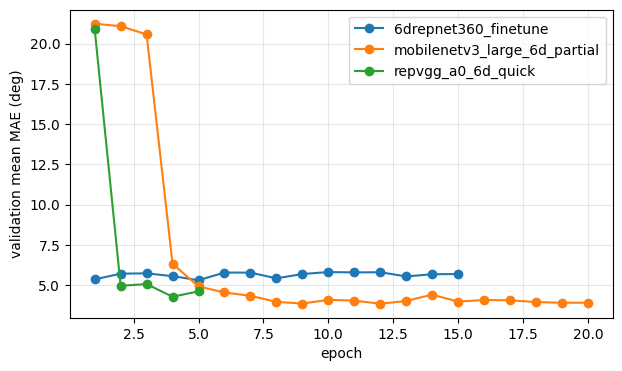

In [ ]:
def load_results(work_dir: "str | Path") -> pd.DataFrame:
    rows = [json.loads(p.read_text()) for p in sorted((Path(work_dir) / "results").glob("*_result.json"))]
    cols = ["run", "params_M", "test_mae_yaw", "test_mae_pitch", "test_mae_roll", "test_mae_mean", "ms_cpu", "ms_gpu", "epochs"]
    df = pd.DataFrame(rows)
    return df[[c for c in cols if c in df.columns]].sort_values("test_mae_mean").round(3).reset_index(drop=True)


display(load_results(WORK_DIR))

fig, ax = plt.subplots(figsize=(7, 4))
for path in sorted((WORK_DIR / "results").glob("*_history.json")):
    hist = json.loads(path.read_text())
    ax.plot([h["epoch"] for h in hist], [h["val_mae_mean"] for h in hist], marker="o", label=path.stem.replace("_history", ""))
ax.set_xlabel("epoch")
ax.set_ylabel("validation mean MAE (deg)")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

## 10. Inference module (what the group's GUI will import)

`HeadPoseEstimator.estimate(face_rgb)` takes the **cropped face** (RGB `uint8`, any size) and returns `{"yaw", "pitch", "roll"}` in degrees. `PoseGate` is the first integration piece: only run recognition when the face is near-frontal. The thresholds are placeholders; tune them with the AUC-by-pose analysis on `verification_pairs_val.txt`.

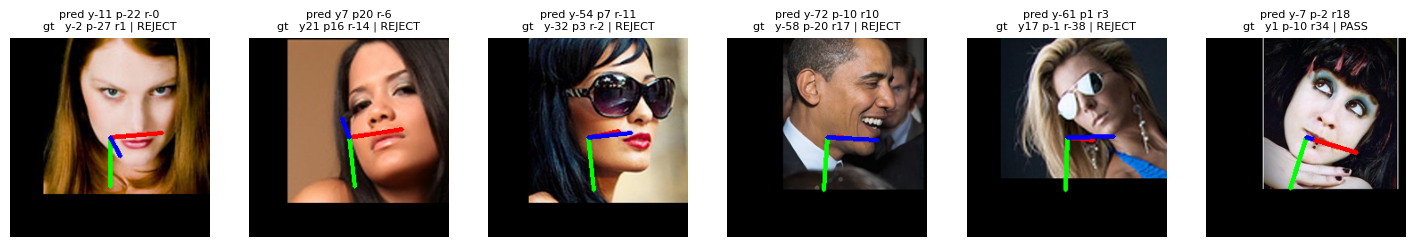

In [ ]:
class HeadPoseEstimator:
    def __init__(self, ckpt_path, device: Optional[torch.device] = None):
        self.device = device or DEVICE
        ckpt = torch.load(ckpt_path, map_location=self.device, weights_only=True)
        saved = ckpt["cfg"]
        self.img_size = saved["img_size"]
        self.model = HeadPoseNet(saved["variant"], saved["head"], pretrained=False).to(self.device).eval()
        self.model.load_state_dict(ckpt["model"])

    @torch.inference_mode()
    def estimate(self, face_rgb: np.ndarray) -> dict:
        if (face_rgb.ndim != 3 or face_rgb.shape[2] != 3 or face_rgb.dtype != np.uint8
                or min(face_rgb.shape[:2]) < MIN_FACE_PX):
            raise ValueError(f"expected an RGB uint8 face crop of at least {MIN_FACE_PX:.0f} px, "
                             f"got shape {face_rgb.shape} dtype {face_rgb.dtype}")
        face = cv2.resize(face_rgb, (self.img_size, self.img_size), interpolation=cv2.INTER_LINEAR)
        x = torch.from_numpy(face).permute(2, 0, 1).float().div(255.0).unsqueeze(0).to(self.device)
        pitch, yaw, roll = (self.model.to_euler(self.model(x))[0] * 180.0 / math.pi).tolist()
        return {"yaw": yaw, "pitch": pitch, "roll": roll}


@dataclass(frozen=True)
class PoseGate:
    max_yaw: float = 25.0
    max_pitch: float = 20.0
    max_roll: float = 30.0

    def is_frontal(self, pose: dict) -> bool:
        return (abs(pose["yaw"]) <= self.max_yaw
                and abs(pose["pitch"]) <= self.max_pitch
                and abs(pose["roll"]) <= self.max_roll)


# demo on AFLW2000: crop with the landmark box, estimate, draw axes, apply the gate
estimator = HeadPoseEstimator(WORK_DIR / "checkpoints" / f"{cfg.tag}.pt")
gate = PoseGate()
fig, axes = plt.subplots(1, 6, figsize=(18, 3.6))
demo_picks = np.random.default_rng(1).choice(len(aflw_index["paths"]), 6, replace=False)
for ax, i in zip(axes, demo_picks, strict=True):
    img = Image.open(aflw_index["paths"][i]).convert("RGB")
    face = np.asarray(crop_face(img, aflw_index["bboxes"][i], margin=TEST_MARGIN).resize((estimator.img_size, estimator.img_size)))
    pose = estimator.estimate(face)
    gt = np.degrees(aflw_index["poses"][i])
    ax.imshow(draw_axis(face, pose["yaw"], pose["pitch"], pose["roll"], size=60))
    ax.set_title(f"pred y{pose['yaw']:.0f} p{pose['pitch']:.0f} r{pose['roll']:.0f}\n"
                 f"gt   y{gt[1]:.0f} p{gt[0]:.0f} r{gt[2]:.0f} | {'PASS' if gate.is_frontal(pose) else 'REJECT'}", fontsize=8)
    ax.axis("off")
plt.show()